# Reconstrucción en condiciones ideales

Continuaremos utilizando el vector $x_{\text{fantoma}}$ del Ejercicio 1 y las matrices $A_2$, $A_4$ y $A_7$ construidas anteriormente. Trabajaremos con mediciones ideales, sin ruido, para observar cómo el rango de la matriz de proyección afecta la reconstrucción. En particular, $A_7$ tiene rango columna completo, mientras que $A_2$ y $A_4$ no determinan una solución única.


In [2]:

import numpy as np
import matplotlib.pyplot as plt


#Matriz de 8x8 que representa el fantoma
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Vector de 64 elementos que representa el fantoma
x_v_fantoma=X_fantoma.reshape(-1)

# Como los archivos tienen que ser autoconclusivos copiamos la funcion mascara_rayo del ejercicio 2.
def mascara_rayo(n, direccion, s):
    M = np.zeros((n, n)) #creamos la matriz de ceros
    i, j = np.ogrid[:n, :n] #indices de la matriz
    condicion=( i*direccion[0] + j*direccion[1] == s) #si  el pixel (i, j) es atravesado por el rayo r, lo marcamos con un 1
    M[condicion] = 1
    return M

def matriz_proyeccion(n, direcciones):
    i, j = np.indices((n,n))
    filas=[]
    rayos=[]
    A=[]
   
    for(alfa,beta) in direcciones:
       
       S= alfa*i+beta*j
       valores_s=np.unique(S)

       #Por cada rayo
       for s in valores_s:
           M=mascara_rayo(n,(alfa,beta),s) 
           filas.append(M.reshape(-1))
           rayos.append(((alfa,beta),int(s)))

    A = np.array(filas, dtype=float)
    return A, rayos

D2=[(1, 0), (0, 1)]
D4=D2+[(1,1),(1,-1)]
D7=D4+[(2,1),(1,2),(3,1)]

#Matrices de proyeccion
A2, rayos2 = matriz_proyeccion(8, D2)
A4, rayos4 = matriz_proyeccion(8, D4)
A7, rayos7 = matriz_proyeccion(8, D7)

#### a) Para cada $k \in \{2, 4, 7\}$, generar las mediciones $b_k = A_k\,x_{\text{fantoma}}$ y resolver el sistema mediante `np.linalg.lstsq` para obtener una reconstrucción $\hat{x}_k$. En los casos sin solución única, esta función devolverá una solución de norma mínima.

In [3]:
matrices={2: A2, 4: A4, 7: A7} #asocia k con su matriz
mediciones={}  #bk
reconstrucciones={} #x̂k

for k, A in matrices.items():
    #mediciones sin ruido
    b = A @ x_v_fantoma  #producto matriz vector 

    # Reconstrucción por mínimos cuadrados (si no hay solución única, devuelve la de norma mínima).
    # lstsq devuelve: la solución, la suma de los residuos al cuadrado, el rango de A y sus valores singulares.
    # Solo nos interesa la solución, el resto se descarta con _.
    x_hat, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
    mediciones[k] = b
    reconstrucciones[k] = x_hat
    print(f"A{k}: b tiene {b.shape[0]} componentes, x̂ tiene {x_hat.shape[0]} componentes")




A2: b tiene 16 componentes, x̂ tiene 64 componentes
A4: b tiene 46 componentes, x̂ tiene 64 componentes
A7: b tiene 119 componentes, x̂ tiene 64 componentes


 Como las mediciones no tienen ruido, $b_k = A_k x_{\text{fantoma}}$ es una combinación lineal de las columnas de $A_k$ con los píxeles del fantoma como coeficientes, es decir, $b_k \in \text{Col}(A_k)$. Por lo tanto, el sistema siempre tiene solución (al menos el propio fantoma). Por lo visto en el Ejercicio 4, la solución es única para $A_7$ y hay infinitas para $A_2$ y $A_4$, de la forma $x_p + \text{Nul}(A_k)$.

`lstsq`devuelve la **norma mínima**, no porque sea necesariamente la real, sino porque es un criterio especifico para hacerlo. Para ver cuál es, se usan dos resultados:

- **$\text{Nul}(A_k)$ es el complemento ortogonal de $\text{Fil}(A_k)$:** $A_k v = 0$ significa que $v$ tiene producto punto cero con cada fila de $A_k$. En el problema, el espacio fila es lo que el escáner "ve" (cada medición es el producto punto de una fila con la imagen) y el espacio nulo, lo que no ve.
- **Descomposición ortogonal:** todo vector se escribe de manera única como $x = x_{\text{fila}} + x_{\text{nul}}$, con $x_{\text{fila}} \in \text{Fil}(A_k)$ y $x_{\text{nul}} \in \text{Nul}(A_k)$.

Como $A_k x_{\text{nul}} = 0$, las mediciones solo dependen de $x_{\text{fila}}$, todas las soluciones tienen el mismo $x_{\text{fila}}$ (el del fantoma) y solo se diferencian en $x_{\text{nul}}$. `lstsq` se queda con la que tiene $x_{\text{nul}} = 0$, es decir, $\hat{x}_k = x_{\text{fila}}$ conserva lo que el escáner ve y no agrega nada en lo que no ve


#### b) Para cada reconstrucción, calcular el residuo $r_k = b_k - A_k\,\hat{x}_k$ y su norma. Calcular también el error relativo dividiendo $\|\hat{x}_k - x_{\text{fantoma}}\|$ por $\|x_{\text{fantoma}}\|$. Resumir en una tabla el rango de $A_k$, la norma del residuo y el error relativo.


In [4]:
norma_fantoma = np.linalg.norm(x_v_fantoma)

#Construyo la tabla
print(f"{'Matriz':<8}{'Rango':>7}{'dim Nul':>9}{'||r_k||':>14}{'Error relativo':>17}")

#Por cada matriz de direcciones
for k, A in matrices.items():
    #bk= Ak * x_fantoma
    b = mediciones[k]
    # x̂k
    x_hat = reconstrucciones[k]

    rango = np.linalg.matrix_rank(A)
    residuo = b - A @ x_hat
    norma_residuo = np.linalg.norm(residuo)
    error_relativo = np.linalg.norm(x_hat - x_v_fantoma) / norma_fantoma

    print(f"A{k:<7}{rango:>7}{64 - rango:>9}{norma_residuo:>14.2e}{error_relativo:>17.4f}")

Matriz    Rango  dim Nul       ||r_k||   Error relativo
A2           15       49      2.78e-15           0.4689
A4           39       25      1.31e-14           0.1365
A7           64        0      1.26e-14           0.0000


El **residuo** $r_k = b_k - A_k\hat{x}_k$ indica si la reconstrucción reproduce las mediciones. El **error relativo** indica si la reconstrucción se parece a la imagen real, que en una tomografía real es lo desconocido.

En este caso:
- El **residuo** es prácticamente cero en los tres casos porque como $b_k \in \text{Col}(A_k)$ el sistema tiene solución, es decir, existe una imagen que reproduce exactamente las mediciones.
- El **error relativo**, en cambio, es muy distinto: ≈ 47 % para $A_2$, ≈ 14 % para $A_4$ y prácticamente 0 para $A_7$. Disminuye a medida que aumenta el rango de la matriz. Solo con $A_7$, que tiene rango completo y por lo tanto solución única , la reconstrucción coincide con el fantoma.


#### c) Visualizar, para cada caso, la imagen original, la reconstrucción y la diferencia entre ambas, utilizando la misma escala de color. Explicar por qué un residuo cercano a cero no garantiza que la imagen original haya sido recuperada correctamente y relacionar el resultado con el espacio nulo de $A_k$.

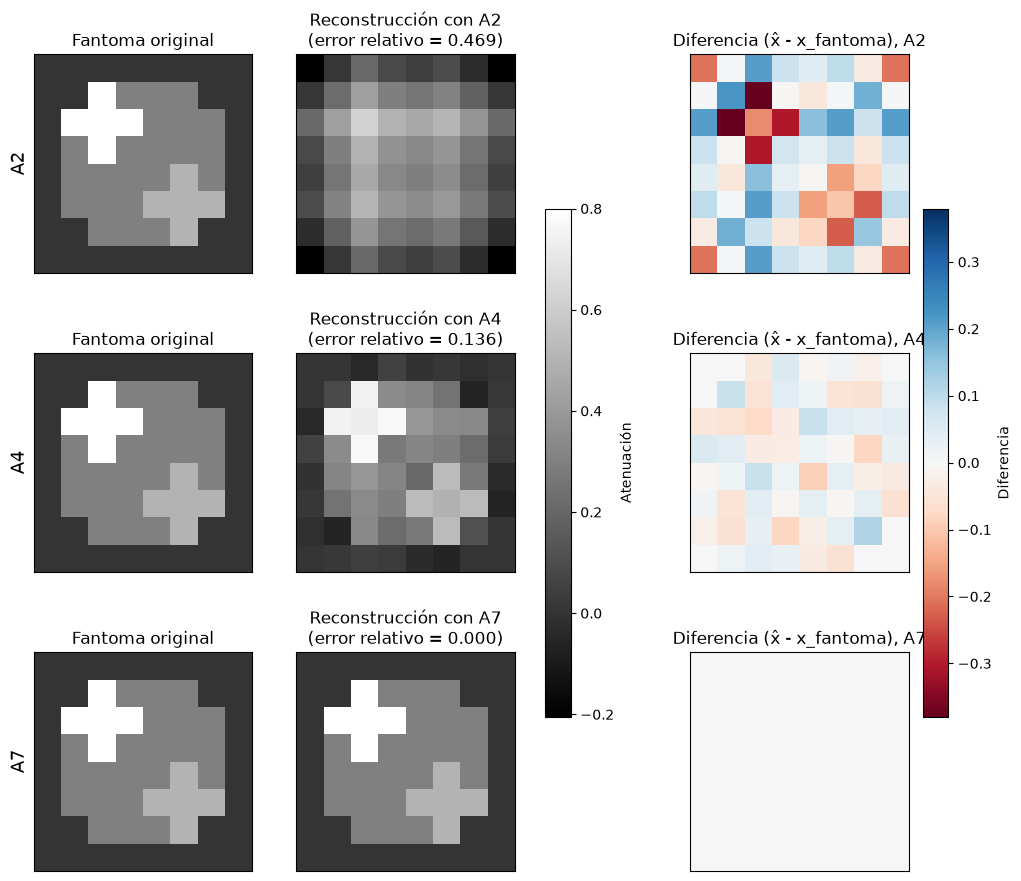

In [5]:
# Escala común para el fantoma y todas las reconstrucciones
imagenes = [X_fantoma] + [reconstrucciones[k].reshape(8, 8) for k in matrices]
vmin = min(img.min() for img in imagenes)
vmax = max(img.max() for img in imagenes)

# Escala común (simétrica) para todas las diferencias
diferencias = {k: reconstrucciones[k].reshape(8, 8) - X_fantoma for k in matrices}
lim = max(np.abs(d).max() for d in diferencias.values())

fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for fila, k in enumerate(matrices):
    X_hat = reconstrucciones[k].reshape(8, 8)
    error_relativo = np.linalg.norm(reconstrucciones[k] - x_v_fantoma) / norma_fantoma

    im0 = axes[fila, 0].imshow(X_fantoma, cmap='gray', vmin=vmin, vmax=vmax)
    axes[fila, 0].set_title('Fantoma original')

    im1 = axes[fila, 1].imshow(X_hat, cmap='gray', vmin=vmin, vmax=vmax)
    axes[fila, 1].set_title(f'Reconstrucción con A{k}\n(error relativo = {error_relativo:.3f})')

    im2 = axes[fila, 2].imshow(diferencias[k], cmap='RdBu', vmin=-lim, vmax=lim)
    axes[fila, 2].set_title(f'Diferencia (x̂ - x_fantoma), A{k}')

    axes[fila, 0].set_ylabel(f'A{k}', fontsize=13)

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

# Una barra de colores para las imágenes y otra para las diferencias
fig.colorbar(im1, ax=axes[:, :2], shrink=0.6, label='Atenuación')
fig.colorbar(im2, ax=axes[:, 2], shrink=0.6, label='Diferencia')

plt.savefig('figuras/ejercicio_05c.png', dpi=150, bbox_inches='tight')
plt.show()


- **$A_2$:** como el escáner solo mide las sumas por filas y por columnas (como vimos en el ejercicio 3e), la reconstrucción no logra recuperar las formas del fantoma: queda una imagen borrosa, los bordes dejan de valer 0 y las esquinas toman valores negativos. Los errores más grandes están en la cruz de 0.8.

- **$A_4$:** la reconstrucción ya conserva la forma general del fantoma, pero quedan errores más chicos repartidos en toda la imagen.

- **$A_7$:** la reconstrucción es igual al fantoma y la diferencia es nula en toda la imagen.

Un residuo cercano a cero no garantiza haber recuperado la imagen porque solo mide si la reconstrucción reproduce las mediciones, no si es la imagen correcta. Por lo visto en el Ejercicio 4a, cuando $\text{Nul}(A_k) \neq \{0\}$, para cualquier $v \in \text{Nul}(A_k)$ se cumple

$$A_k(\hat{x}_k + v) = A_k\hat{x}_k + A_k v = A_k\hat{x}_k$$

es decir, todas las imágenes $\hat{x}_k + v$ tienen exactamente el mismo residuo. Entre ellas está el fantoma, pero a partir de las mediciones no hay forma de saber cuál es.

Esto se ve en los resultados con $A_2$ y $A_4$, que tienen espacio nulo distinto de $\{0\}$, el residuo es prácticamente cero pero la reconstrucción no coincide con el fantoma. Además, cuanto más grande es el espacio nulo, mayor es el error ($\dim(\text{Nul}) = 49$: ≈ 47 %; $\dim(\text{Nul}) = 25$: ≈ 14 %), porque hay más imágenes compatibles con las mismas mediciones. Solo cuando el espacio nulo es $\{0\}$, como en $A_7$, la solución es única y un residuo nulo garantiza haber recuperado la imagen original.